## 📊 최종 데이터셋 (Feature Definition)
- df_analysis 데이터셋의 주요 변수(Feature) 및 타겟 라벨(Target) 정의
- 모든 피처는 데이터 누수(Data Leakage)를 방지하기 위해 Cut-off 기준일(2020-03-03) 이전의 과거 531일 데이터만을 활용하여 생성

| 피처 그룹 | 피처 명 (Column Name) | 비즈니스적 의미 및 설명 | 전처리 및 분석 고려사항 |
| :--- | :--- | :--- | :--- |
| 타겟 라벨 | churn | 이탈 여부 (Target Variable)<br>• 1: Cut-off 이후 203일간 구매 기록 없음 (이탈)<br>• 0: Cut-off 이후 203일간 최소 1회 이상 구매 (유지) | 모델이 예측해야 하는 최종 정답지 |
| 고객 식별자 | customer_id | 고객을 식별하는 고유 해시 ID | 모델 학습 시에는 제외해야 하는 식별용 컬럼 |
| RFM 기반 행동 특징 | frequency | 구매 빈도: 과거 구간 동안의 총 구매 상품(아이템) 건수 | 고객의 서비스 충성도를 나타내는 핵심 지표 |
| | price_mean | 평균 구매 금액: 유저가 구매한 상품 가격의 평균값 | 고객의 평균적인 객단가 및 구매력 파악 |
| | price_sum | 총 구매 금액: 과거 구간 동안 지출한 총 금액 | 가치 있는 우량 고객(VVIP)을 판별하는 지표 |
| | price_max | 최고 구매 금액: 유저가 구매한 상품 중 가장 비싼 상품의 가격 | 고가 상품(럭셔리 라인 등)에 대한 수용도 |
| | recency | 최근성: Cut-off 기준일로부터 유저의 마지막 구매일까지 흐른 일수 | 주의: 이탈 라벨과 가장 강한 상관관계를 가짐 (Shortcut Learning 주의) |
| 활동성 (윈도우) | frequency_last_90d | 최근 90일간의 구매 상품 건수 | 최근 3개월간 활동이 활발했는지 나타내는 단기 지표 (결측치는 0 처리 완료) |
| | frequency_last_180d | 최근 180일간의 구매 상품 건수 | 최근 6개월간의 활동성 추이 반영 (결측치는 0 처리 완료) |
| 구매 주기 | avg_purchase_interval | 평균 구매 간격: 유저의 구매 사이사이 평균 공백기(일수) | 값이 작을수록 빈번하게 방문하는 유저임을 의미함 |
| | std_purchase_interval | 구매 간격 편차: 구매 주기 일수의 표준편차 | 값이 작을수록 규칙적인 주기성(Seasonality)을 가짐<br>※ 주의: 구매 이력이 1건인 유저는 NaN 발생 |
| 구매 다양성 | unique_articles | 과거 동안 구매한 서로 다른 고유 상품(Article)의 개수 | 상품 단에서의 취향 다양성 및 재구매 성향 파악 |
| | unique_product_groups | 과거 동안 구매한 서로 다른 고유 카테고리(그룹)의 개수 | 특정 카테고리에 몰두하는지, 골고루 사는지 파악 |
| 고객 취향 (선호도) | index_group_name | 가장 많이 구매한 인덱스 그룹 이름 (예: Ladieswear 등) | 범주형(Categorical) 변수<br>※ 주의: 모델 입력 전 원-핫 인코딩(get_dummies) 필요 |
| | product_group_name | 가장 많이 구매한 상품 카테고리 이름 (예: Shoes 등) | 범주형(Categorical) 변수<br>※ 주의: 모델 입력 전 원-핫 인코딩(get_dummies) 필요 |
| 고객 메타 | age | 고객의 연령(나이) | 연속형 변수 (결측치 처리 전략 필요) |
| | FN | 패션 뉴스(Fashion News) 알림 수신 여부 (1 또는 NaN) | 마케팅 채널 결합도 확인 변수 |
| | Active | 고객의 서비스 활성화 상태 (1 또는 NaN) | 마케팅 채널 결합도 확인 변수 |
| | club_member_status | 클럽 회원 자격 상태 (예: Active, Pre-create 등) | 범주형 변수 |
| | fashion_news_frequency | 패션 뉴스 수신 빈도 (예: Regular, Monthly 등) | 범주형 변수 |

In [ ]:
# for data manipulation
import numpy as np
import pandas as pd

# for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# for data splitting, transforming and model training
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

# Import Warnings
import warnings
warnings.simplefilter(action="ignore")

In [ ]:
# Setting Configurations:

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

# Analyze the numerical and categorical variables

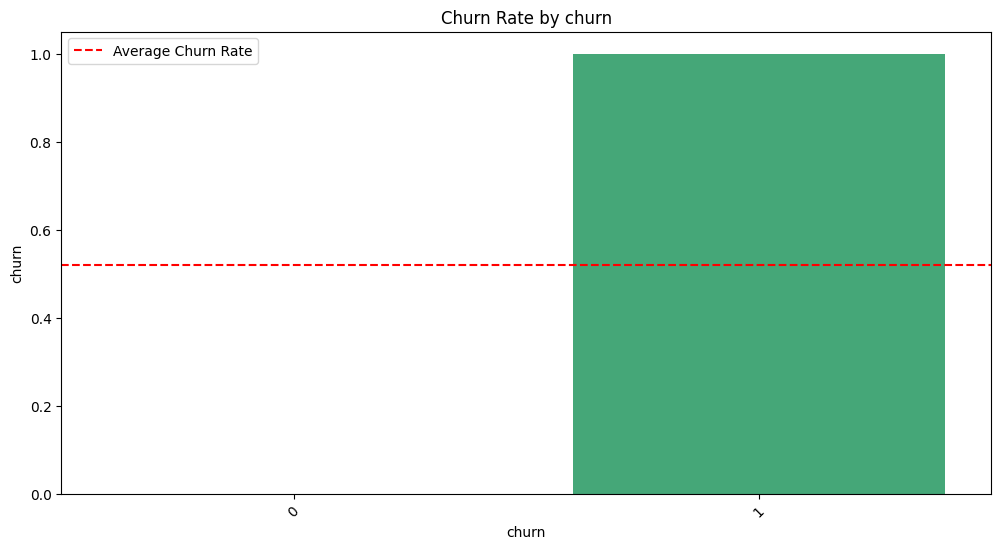

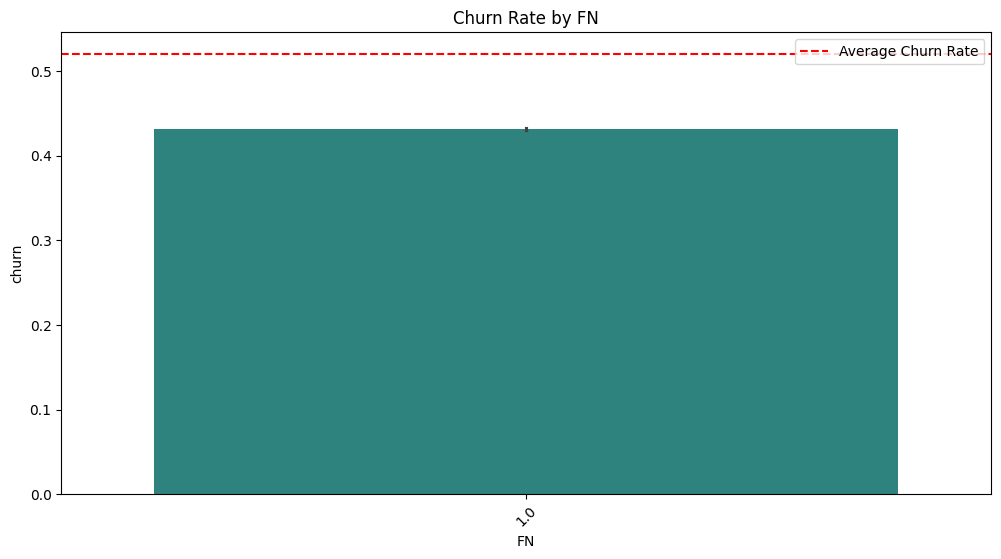

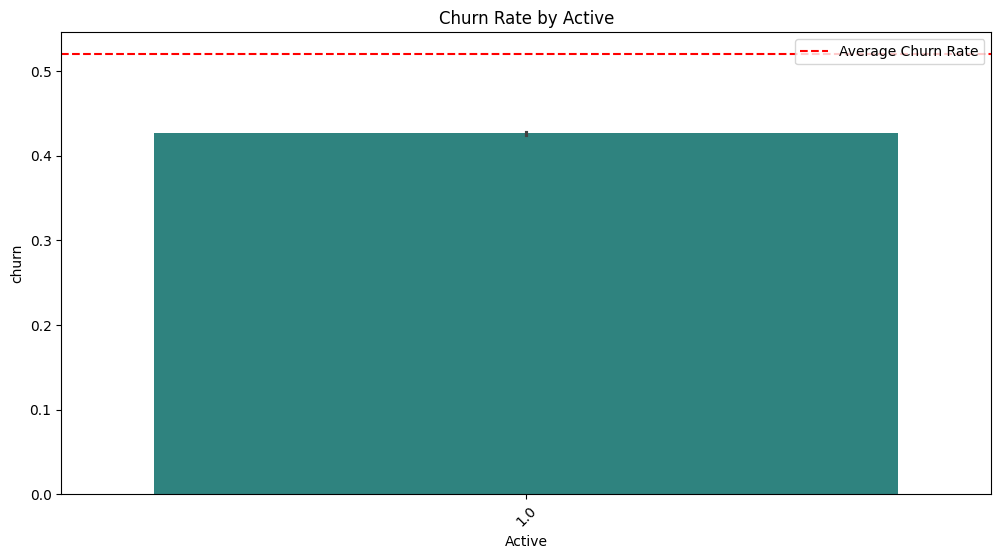

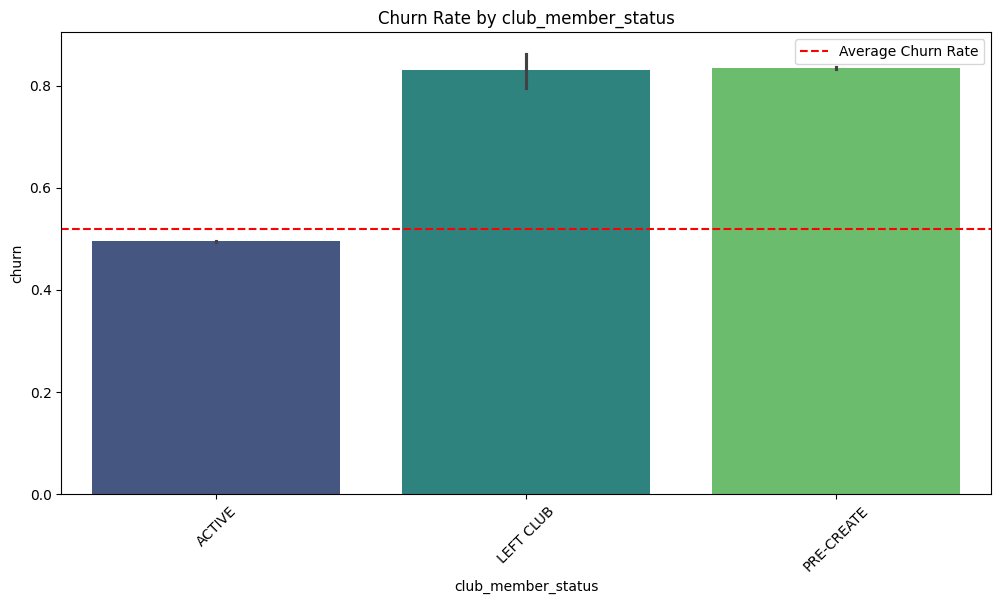

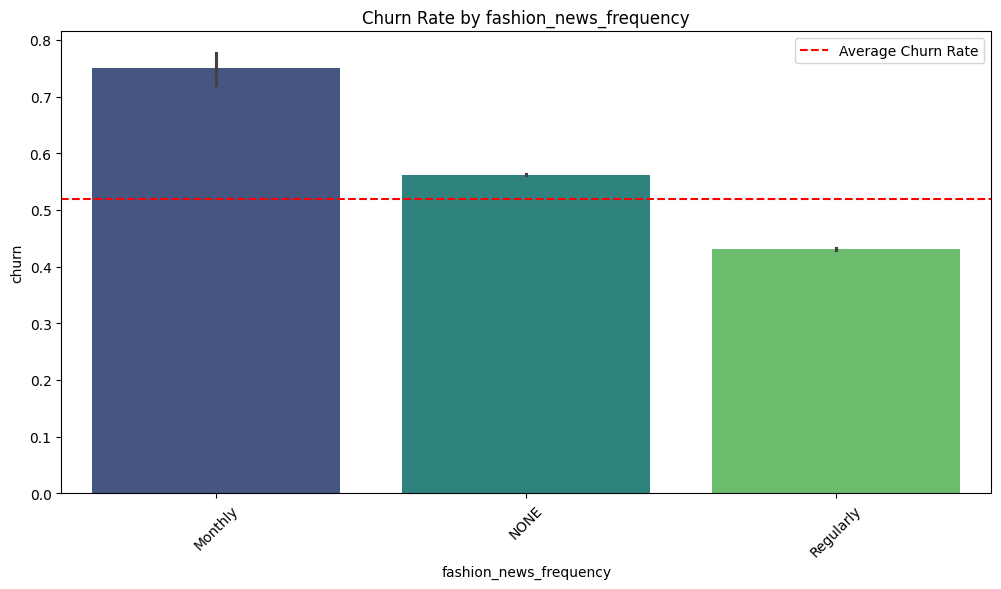

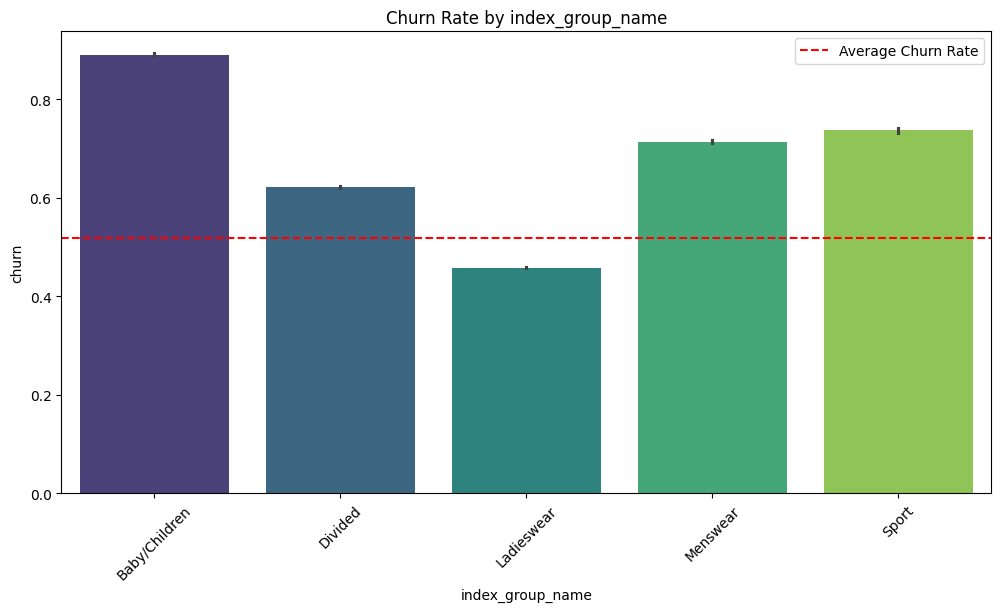

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def target_vs_category_visual(dataframe, target, categorical_col):
    plt.figure(figsize=(12, 6))
    
    # 1. float16 에러 방지를 위해 임시로 타입 변환 후 데이터 준비
    # 카테고리별 이탈률(mean)을 계산합니다.
    df_temp = dataframe.copy()
    if df_temp[categorical_col].dtype == 'float16':
        df_temp[categorical_col] = df_temp[categorical_col].astype('float32')
        
    # 2. 카테고리별 이탈률(평균) 시각화
    # Churn이 0, 1이므로 평균을 내면 곧 이탈률이 됩니다.
    sns.barplot(x=categorical_col, y=target, data=df_temp, palette='viridis')
    
    # 전체 평균 이탈률 선 표시 (기준점)
    plt.axhline(dataframe[target].mean(), color='red', linestyle='--', label='Average Churn Rate')
    
    plt.title(f"Churn Rate by {categorical_col}")
    plt.xticks(rotation=45)
    plt.legend()
    plt.show()

# 시각화 실행
# cat_cols에 FN, Active 등이 포함되어 있다면 이 코드가 에러 없이 돌아갑니다.
for col in cat_cols:
    target_vs_category_visual(df, "churn", col)

# Perform a missing observation analysis.

In [ ]:
def missing_values_table(dataframe, na_name=False):
    na_columns = [col for col in dataframe.columns if dataframe[col].isnull().sum() > 0]

    n_miss = dataframe[na_columns].isnull().sum().sort_values(ascending=False)
    ratio = (dataframe[na_columns].isnull().sum() / dataframe.shape[0] * 100).sort_values(ascending=False)
    missing_df = pd.concat([n_miss, np.round(ratio, 2)], axis=1, keys=['n_miss', 'ratio'])
    print(missing_df, end="\n")

    if na_name:
        return na_columns


missing_values_table(df)

                        n_miss  ratio
Active                  885358 66.170
FN                      873035 65.250
fashion_news_frequency   15961  1.190
age                      15555  1.160
club_member_status        5989  0.450


In [ ]:
# 결측치 처리!! 이건 EDA 다음 단계에서 하기
# 
# # 1. 마케팅 관련 결측치는 0으로 (거부 의사로 간주)
df['FN'] = df['FN'].fillna(0)
df['Active'] = df['Active'].fillna(0)

# 2. 나이는 중앙값으로 채우기
df['age'] = df['age'].fillna(df['age'].median())

# 3. 범주형 변수의 결측치는 새로운 카테고리 'UNKNOWN'으로 통일
cat_fix_cols = ['club_member_status', 'fashion_news_frequency']
for col in cat_fix_cols:
    # 카테고리 타입에 'UNKNOWN' 추가 후 결측치 채우기
    if 'UNKNOWN' not in df[col].cat.categories:
        df[col] = df[col].cat.add_categories(['UNKNOWN'])
    df[col] = df[col].fillna('UNKNOWN')

print("--- 결측치 처리 완료 ---")
print(df.isnull().sum())

--- 결측치 처리 완료 ---
customer_id               0
first_buy                 0
last_buy                  0
tenure                    0
recency                   0
threshold                 0
churn                     0
frequency                 0
price_mean                0
price_sum                 0
FN                        0
Active                    0
club_member_status        0
fashion_news_frequency    0
age                       0
index_group_name          0
product_group_name        0
dtype: int64


# Perform correlation analysis.

In [ ]:
corr_matrix = df[num_cols].corr()
corr_matrix

,tenure,recency,frequency,price_mean,price_sum,FN,Active,age
tenure,1.000,0.202,0.340,-0.019,0.316,0.092,0.089,0.071
recency,0.202,1.000,-0.372,0.075,-0.342,-0.105,-0.116,0.094
frequency,0.340,-0.372,1.000,-0.036,0.959,0.101,0.105,-0.015
price_mean,-0.019,0.075,-0.036,1.000,0.069,-0.039,-0.038,0.122
price_sum,0.316,-0.342,0.959,0.069,1.000,0.087,0.091,0.005
FN,0.092,-0.105,0.101,-0.039,0.087,1.000,0.980,0.035
Active,0.089,-0.116,0.105,-0.038,0.091,0.980,1.000,0.038
age,0.071,0.094,-0.015,0.122,0.005,0.035,0.038,1.000


In [ ]:
# 1. 숫자형 데이터만 있는 데이터프레임 따로 만들기
# churn을 포함한 숫자형 컬럼만 필터링합니다.
numeric_df = df.select_dtypes(include=['number'])

# 2. 상관계수 구하기
# 이제 문자열 ID나 날짜 데이터가 빠졌으므로 에러 없이 돌아갑니다.
churn_corr = numeric_df.corr()['churn'].sort_values(ascending=False)

print("--- Churn과의 상관계수 순위 ---")
print(churn_corr)

--- Churn과의 상관계수 순위 ---
churn         1.000
recency       0.762
price_mean    0.078
age           0.069
threshold    -0.099
FN           -0.128
Active       -0.134
tenure       -0.186
price_sum    -0.385
frequency    -0.419
Name: churn, dtype: float64


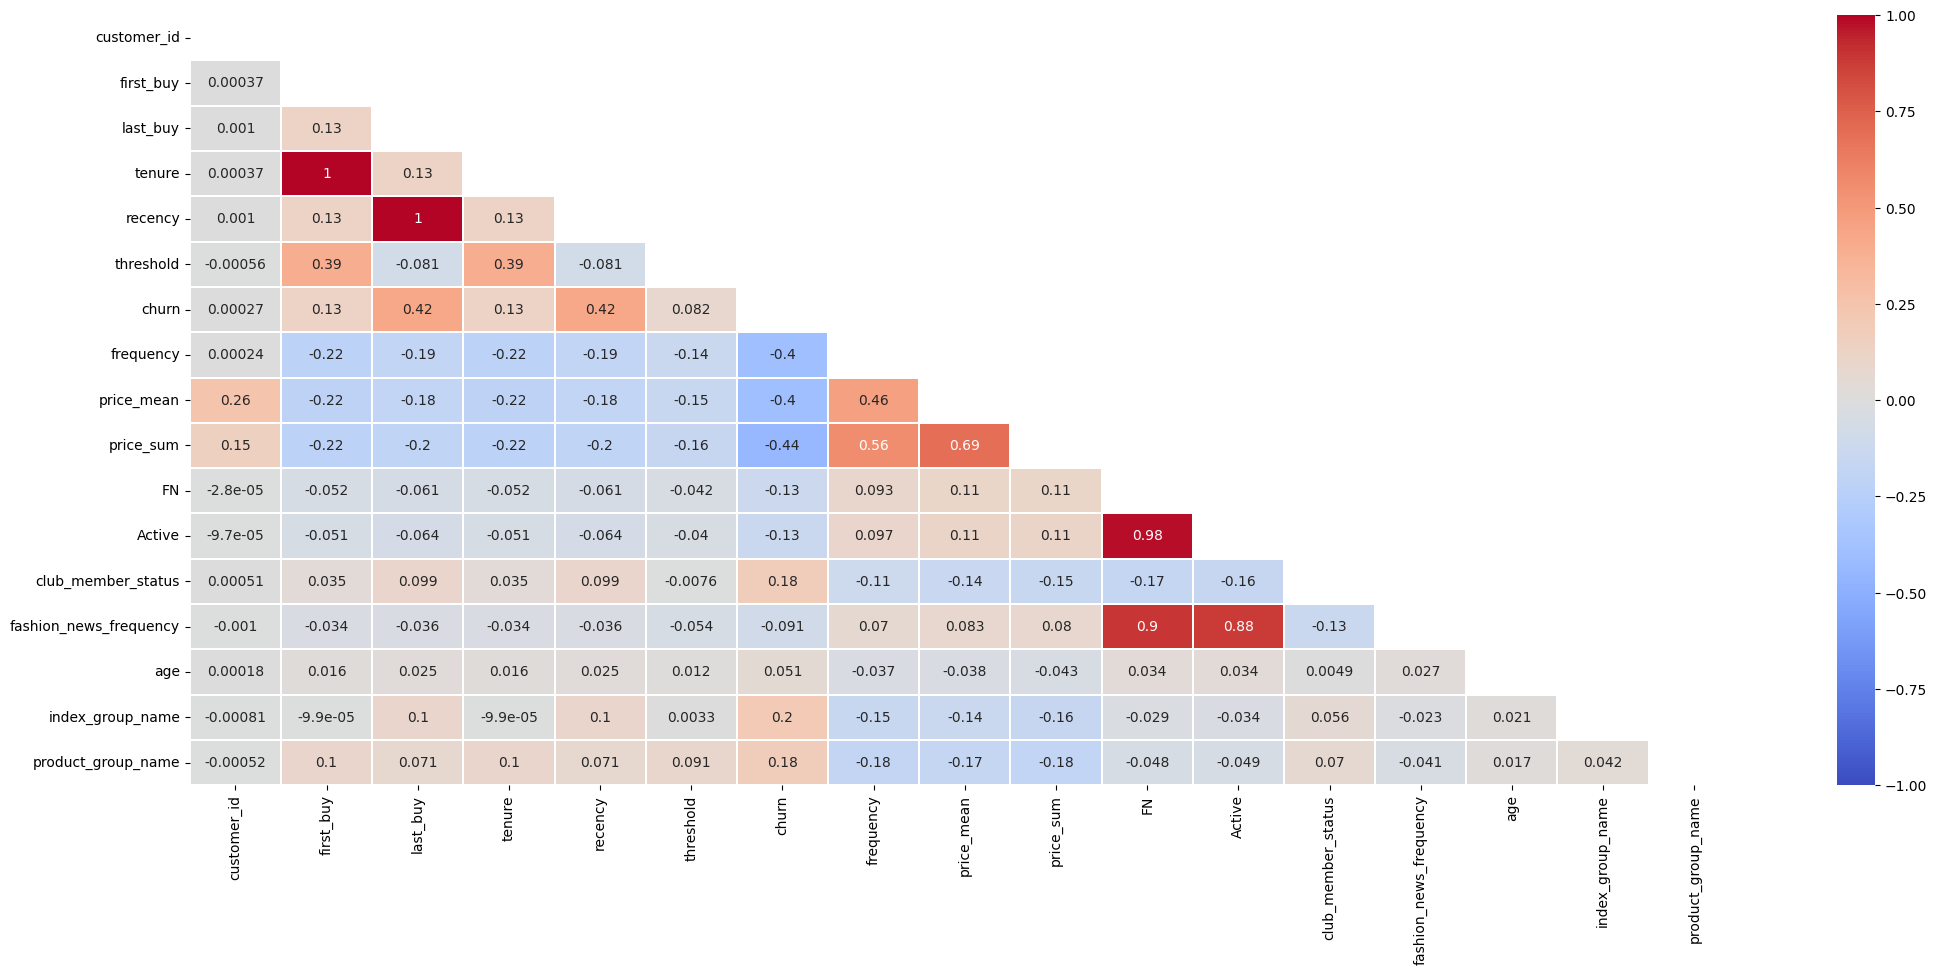

In [ ]:
# Correlation between all variables
plt.figure(5, figsize=(25, 10))
corr = df.apply(lambda x: pd.factorize(x)[0]).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
ax = sns.heatmap(corr, mask=mask, xticklabels=corr.columns, yticklabels=corr.columns, annot=True, linewidths=.2, cmap='coolwarm', vmin=-1, vmax=1)

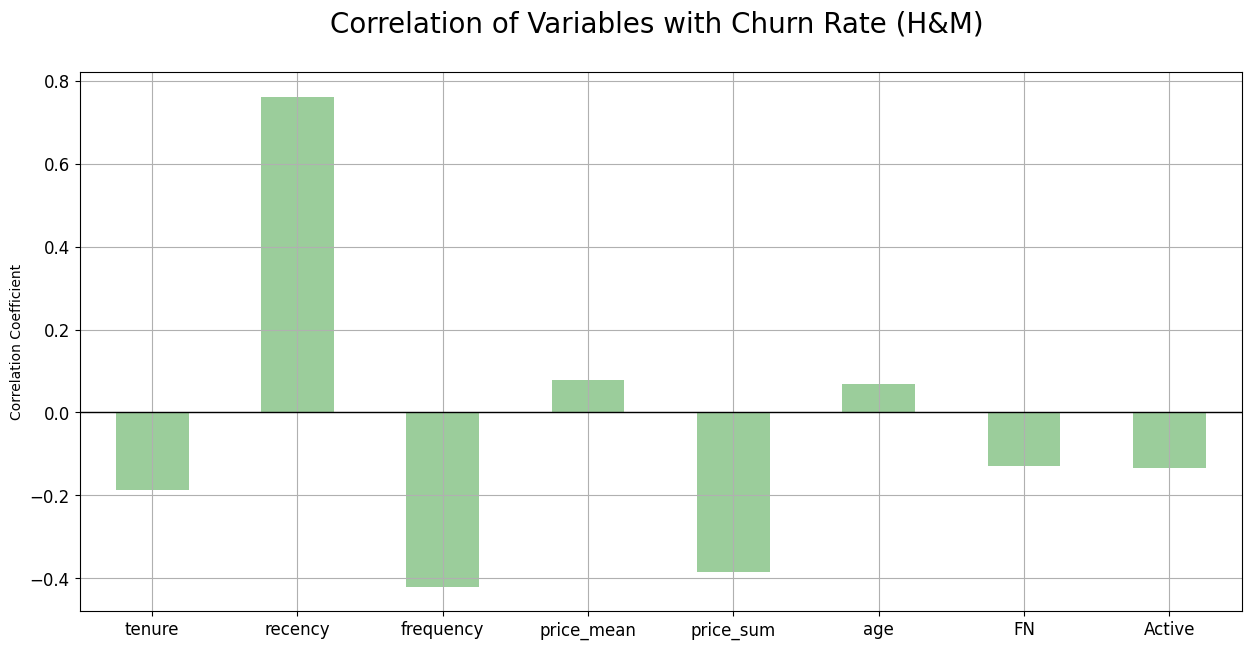

In [ ]:
import matplotlib.pyplot as plt

# 1. 시각화할 수치형 변수들 선택 (H&M 데이터셋 전용)
# 분석 목적에 맞는 핵심 변수들만 추렸습니다.
ds_corr = df[['tenure', 'recency', 'frequency', 'price_mean', 'price_sum', 'age', 'FN', 'Active']]

# 2. Churn과의 상관계수 계산
correlations = ds_corr.corrwith(df.churn)

# 3. 시각화 설정
plt.figure(figsize=(15, 8))
correlations.plot.bar(
    figsize = (15, 7),
    fontsize = 12,
    color = '#9BCD9B', # 부드러운 녹색 계열
    rot = 0,           # 가독성을 위해 글자를 똑바로 세움
    grid = True
)

# 차트 디자인 개선
plt.title('Correlation of Variables with Churn Rate (H&M) \n', 
          horizontalalignment="center", fontstyle = "normal", 
          fontsize = "20", fontfamily = "sans-serif")
plt.axhline(0, color='black', linewidth=1) # 기준선 추가
plt.ylabel('Correlation Coefficient')
plt.show()


📑 Analysis: Correlation with Churn Rate
By looking at the correlation results, we can make the following comments:

1. Recency as the Primary Predictor (Positive Correlation)
Comment: recency shows the strongest positive correlation with the churn rate.

Insight: 마지막 구매 이후 경과일이 길어질수록 이탈 가능성이 기하급수적으로 높아집니다. 이는 님이 설계한 이탈 정의가 데이터의 실제 흐름을 매우 강력하게 반영하고 있음을 시사합니다. 이탈 징후를 포착하는 가장 즉각적인 'Red Flag' 지표입니다.

2. Loyalty Metrics as Defensive Barriers (Negative Correlation)
Comment: frequency, price_sum, and tenure exhibit significant negative correlations with churn.

Insight: 구매 횟수가 많고, 총 지출액이 크며, 가입 기간이 길수록 이탈률은 낮아집니다. 특히 frequency가 높을수록 고객은 브랜드에 대한 관성이 생기며, 이는 이탈을 막는 심리적·행동적 방어막 역할을 합니다.

3. The Power of Marketing Engagement
Comment: FN (Fashion News) and Active status are negatively correlated with churn, though the magnitude is lower than behavioral metrics.

Insight: 마케팅 메시지를 수신하고 활동 상태가 활성화된 고객일수록 이탈 확률이 낮습니다. 브랜드와의 지속적인 소통 채널을 열어두는 것이 고객 유지(Retention)에 긍정적인 영향을 미치고 있음을 보여줍니다.

4. Low Impact of Demographic & Unit Price Factors
Comment: age and price_mean show near-zero or very weak correlations with the churn label.

Insight: 나이나 건당 평균 구매 금액은 고객이 떠날지 말지를 결정하는 결정적인 요인이 아닙니다. 즉, "부유한 고객(High price_mean)이나 특정 연령층이 더 충성도가 높다"는 가설은 본 데이터셋에서 성립하지 않으며, 이탈 방지 전략은 인구통계학적 접근보다 행동 기반(Behavior-based) 접근이 훨씬 효과적임을 의미합니다.

# Perform the encoding operations.

In [ ]:
le = LabelEncoder()

binary_cols = [col for col in df.columns if df[col].dtype not in [int, float]
               and df[col].nunique() == 2]

def label_encoder(dataframe, binary_col):
    labelencoder = LabelEncoder()
    dataframe[binary_col] = labelencoder.fit_transform(dataframe[binary_col])
    return dataframe

for col in binary_cols:
    df = label_encoder(df, col)

def one_hot_encoder(dataframe, categorical_cols, drop_first=True):
    dataframe = pd.get_dummies(dataframe, columns=categorical_cols, drop_first=drop_first)
    return dataframe

ohe_cols = [col for col in df.columns if 30 >= df[col].nunique() > 2]

df = one_hot_encoder(df, ohe_cols)

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338029 entries, 0 to 1338028
Data columns (total 40 columns):
 #   Column                                    Non-Null Count    Dtype         
---  ------                                    --------------    -----         
 0   customer_id                               1338029 non-null  str           
 1   first_buy                                 1338029 non-null  datetime64[us]
 2   last_buy                                  1338029 non-null  datetime64[us]
 3   tenure                                    1338029 non-null  int32         
 4   recency                                   1338029 non-null  int32         
 5   threshold                                 1338029 non-null  int32         
 6   churn                                     1338029 non-null  int64         
 7   frequency                                 1338029 non-null  int32         
 8   price_mean                                1338029 non-null  float32       
 9   price_sum    

# Standardize for numeric variables.

In [ ]:
num_cols = [col for col in num_cols if col not in "customerID"]
scaler = StandardScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])

df[num_cols].head()

,tenure,recency,frequency,price_mean,price_sum,FN,Active,age
0,0.571,-1.005,-0.068,0.159,-0.008,-0.730,-0.715,0.888
1,1.043,-0.738,1.577,0.113,1.611,-0.730,-0.715,-0.801
2,1.048,-1.050,-0.144,0.742,0.038,-0.730,-0.715,-0.871
3,-0.226,1.049,-0.549,0.130,-0.496,-0.730,-0.715,1.240
4,0.941,-0.896,-0.271,0.529,-0.157,1.370,1.399,1.099


In [ ]:
df.head()

,customer_id,first_buy,last_buy,tenure,recency,threshold,churn,frequency,price_mean,price_sum,FN,Active,age,club_member_status_LEFT CLUB,club_member_status_PRE-CREATE,club_member_status_UNKNOWN,fashion_news_frequency_NONE,fashion_news_frequency_Regularly,fashion_news_frequency_UNKNOWN,index_group_name_Divided,index_group_name_Ladieswear,index_group_name_Menswear,index_group_name_Sport,product_group_name_Bags,product_group_name_Cosmetic,product_group_name_Furniture,product_group_name_Garment Full body,product_group_name_Garment Lower body,product_group_name_Garment Upper body,product_group_name_Garment and Shoe care,product_group_name_Interior textile,product_group_name_Items,product_group_name_Nightwear,product_group_name_Shoes,product_group_name_Socks & Tights,product_group_name_Stationery,product_group_name_Swimwear,product_group_name_Underwear,product_group_name_Underwear/nightwear,product_group_name_Unknown
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,2018-12-27,2020-09-05,0.571,-1.005,203,0,-0.068,0.159,-0.008,-0.730,-0.715,0.888,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,2018-09-21,2020-07-08,1.043,-0.738,203,0,1.577,0.113,1.611,-0.730,-0.715,-0.801,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,2018-09-20,2020-09-15,1.048,-1.050,203,0,-0.144,0.742,0.038,-0.730,-0.715,-0.871,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,2019-06-09,2019-06-09,-0.226,1.049,203,1,-0.549,0.130,-0.496,-0.730,-0.715,1.240,False,False,False,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,2018-10-12,2020-08-12,0.941,-0.896,203,0,-0.271,0.529,-0.157,1.370,1.399,1.099,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False


# Build a model.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# 1. 학습에 사용할 피처(X)와 정답(y) 정의
# customer_id(str), first_buy(datetime), last_buy(datetime)를 확실히 드롭합니다.
X = df.drop(columns=['customer_id', 'first_buy', 'last_buy', 'churn'])
y = df['churn']

# 2. 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=17)

# 3. 모델 학습 (133만 건이므로 n_jobs=-1을 추가해 병렬 처리를 권장합니다)
rf_model = RandomForestClassifier(random_state=46, n_estimators=100, max_depth=10, n_jobs=-1)
rf_model.fit(X_train, y_train)

# 4. 결과 확인
y_pred = rf_model.predict(X_test)
print(f"Accuracy Score: {accuracy_score(y_test, y_pred)}")

Accuracy Score: 0.9807702368407285


              precision    recall  f1-score   support

           0       0.98      0.98      0.98    128505
           1       0.98      0.99      0.98    139101

    accuracy                           0.98    267606
   macro avg       0.98      0.98      0.98    267606
weighted avg       0.98      0.98      0.98    267606



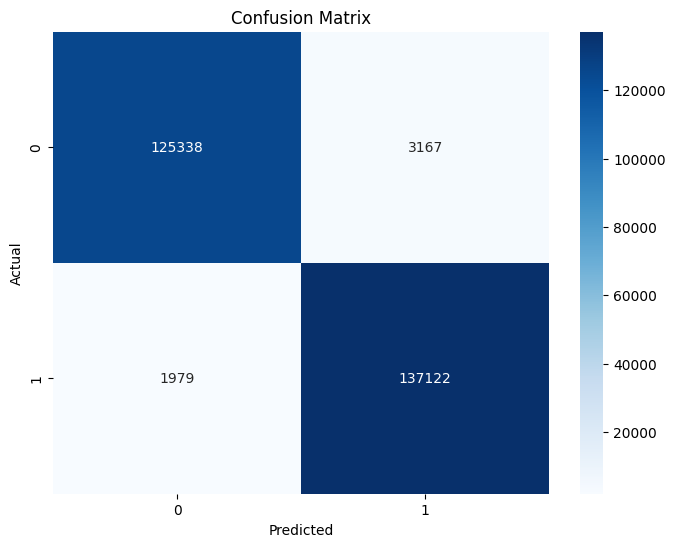

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# 1. 상세 리포트 출력 (Precision, Recall, F1-score)
print(classification_report(y_test, y_pred))

# 2. 혼동 행렬(Confusion Matrix) 시각화
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
# 어떤 변수가 98%를 만들었는지 확인하기
importances = pd.Series(rf_model.feature_importances_, index=X.columns)
print("--- Top 5 Important Features ---")
print(importances.sort_values(ascending=False).head(5))

--- Top 5 Important Features ---
recency     0.587
frequency   0.171
price_sum   0.126
tenure      0.046
threshold   0.031
dtype: float64


In [ ]:
# 1. recency까지 포함해서 제외할 컬럼 리스트 정의
# threshold도 recency와 계산적으로 묶여 있을 수 있으니 함께 제외해보는 것을 추천합니다.
drop_cols_new = ['customer_id', 'first_buy', 'last_buy', 'churn', 'recency', 'threshold']
X_no_recency = df.drop(columns=drop_cols_new)
y = df['churn']

# 2. 데이터 분할
X_train_nr, X_test_nr, y_train_nr, y_test_nr = train_test_split(X_no_recency, y, test_size=0.20, random_state=17)

# 3. 모델 학습 (동일한 조건)
rf_model_nr = RandomForestClassifier(random_state=46, n_estimators=100, max_depth=10, n_jobs=-1)
rf_model_nr.fit(X_train_nr, y_train_nr)

# 4. 결과 확인
y_pred_nr = rf_model_nr.predict(X_test_nr)
from sklearn.metrics import classification_report, accuracy_score
print(f"Accuracy Score (Without Recency): {accuracy_score(y_test_nr, y_pred_nr)}")
print(classification_report(y_test_nr, y_pred_nr))

Accuracy Score (Without Recency): 0.8065252647549008
              precision    recall  f1-score   support

           0       0.79      0.81      0.80    128505
           1       0.82      0.80      0.81    139101

    accuracy                           0.81    267606
   macro avg       0.81      0.81      0.81    267606
weighted avg       0.81      0.81      0.81    267606



In [ ]:
importances_nr = pd.Series(rf_model_nr.feature_importances_, index=X_no_recency.columns)
print("--- New Top 5 Important Features (Without Recency) ---")
print(importances_nr.sort_values(ascending=False).head(5))

--- New Top 5 Important Features (Without Recency) ---
frequency                     0.454
price_sum                     0.367
tenure                        0.041
price_mean                    0.036
index_group_name_Ladieswear   0.028
dtype: float64
